# EDA 1 — Impressions: slates, clicks, position and feedback semantics

Training split only (1,897,835 impressions, 9 to 14 Nov 2019), read from the
processed files written by `1_Data_Preparation/clean_and_validate_data.ipynb`:

* `impressions_train.parquet`: one row per impression (`slate_len`, `n_clicks`, `n_negatives`, `history_len`, ...)
* `candidates_train.parquet`: one row per (impression, candidate) with `position`, `news_code`, `clicked`
* `news_catalogue.parquet`: article metadata

An **impression** is one slate of candidate articles shown to one user. Each candidate carries a label: **1 for click, 0 for no click**.
The order of candidates was shuffled by Microsoft before release.

In [1]:
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import polars as pl  # only for the 70 M-row candidate table; everything small is pandas
import seaborn as sns
from scipy import stats

# Project root = folder that contains 1_Data_Preparation/processed (run 1_Data_Preparation/clean_and_validate_data.ipynb first)
try:
    from google.colab import drive
    drive.mount("/content/drive")
    ROOT = Path(os.environ.get("NEWSREC_ROOT", "/content/drive/MyDrive/BT4222")).expanduser().resolve()
except ImportError:
    ROOT = next(p for p in [Path.cwd(), Path.cwd().parent] if (p / "1_Data_Preparation" / "processed").exists())
PROCESSED = ROOT / "1_Data_Preparation" / "processed"
FIG_DIR = ROOT / "2_EDA" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid", palette=["#2a78d6", "#eb6834", "#1baf7a", "#eda100"])
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
print("Project root:", ROOT)

Project root: /Users/anhminhhoang/BT4222


In [2]:
imp = pl.read_parquet(PROCESSED / "impressions_train.parquet").drop("history")
cand = pl.read_parquet(PROCESSED / "candidates_train.parquet")
news = pl.read_parquet(PROCESSED / "news_catalogue.parquet", columns=["news_code", "category", "in_news_train"])

n_imp, n_users = len(imp), imp["user_code"].n_unique()
n_exp, n_clicks = len(cand), int(cand["clicked"].sum())
print("Impressions:", n_imp)
print("Users:", n_users)
print("Candidate exposures:", n_exp)
print("Clicks:", n_clicks)
print(f"Overall CTR: {100 * n_clicks / n_exp:.2f}%")
print("Time window:", imp["timestamp"].min(), "->", imp["timestamp"].max())

Impressions: 1897835
Users: 667880
Candidate exposures: 70314387
Clicks: 2868998
Overall CTR: 4.08%
Time window: 2019-11-09 00:00:00 -> 2019-11-14 07:30:28


# 1. Slate length and clicks per impression

## 1.1 Slate length
Slate length is the number of candidates in an impression. From the results below:
* Slates run from **2 to 300** candidates; the median is **24** and the mean 37. 28% of slates have at most 10 candidates, 8% more than 100.
* The spikes at **2, 4, 7, 10 and 12** suggest a small number of fixed page templates rather than a continuous ranking cutoff.

count    1897835.0
mean          37.0
std           38.5
min            2.0
5%             2.0
25%            9.0
50%           24.0
75%           51.0
95%          118.0
max          300.0
Name: slate_len, dtype: float64

Most common slate lengths (% of impressions):
slate_len
2     6.90
4     4.76
7     4.00
10    2.85
12    2.45
Name: count, dtype: float64

<= 10 candidates: 28.0% | <= 25: 51.6% | > 100: 8.0%


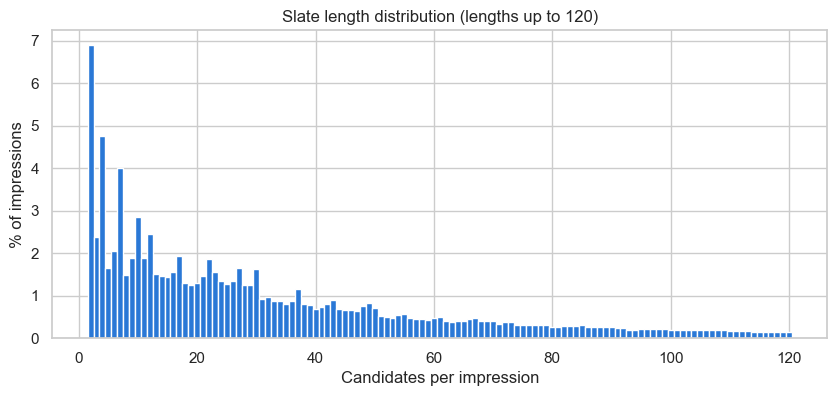

In [3]:
slate = imp["slate_len"].to_pandas()
print(slate.describe(percentiles=[.05, .25, .5, .75, .95]).round(1))

dist = slate.value_counts().sort_index()
pct = 100 * dist / n_imp
print("\nMost common slate lengths (% of impressions):")
print(pct.nlargest(5).round(2))
print(f"\n<= 10 candidates: {pct[pct.index <= 10].sum():.1f}% | <= 25: {pct[pct.index <= 25].sum():.1f}% | > 100: {pct[pct.index > 100].sum():.1f}%")

plt.figure(figsize=(10, 4))
plt.bar(pct.index[pct.index <= 120], pct.values[pct.index <= 120], width=1.0)
plt.title("Slate length distribution (lengths up to 120)")
plt.xlabel("Candidates per impression")
plt.ylabel("% of impressions")
plt.savefig(FIG_DIR / "imp_01_slate_length.png", dpi=150, bbox_inches="tight")
plt.show()

## 1.2 Clicks per impression and the one-click property
* **No impression has zero clicks**: the release only kept impressions that ended in a click. 72.5% contain exactly one click, mean 1.51.
* Because clicks barely grow with slate size, CTR per candidate is close to **1 / slate length** (Spearman correlation between slate
  length and impression CTR is −0.89).

**Model Implications**
* The 4.08% CTR is a click-conditioned number, only comparable within this log, not a platform CTR.
* `slate_len` predicts the label by construction and is **excluded as a feature**; ranking must be evaluated **per impression**.

Impressions with 0 clicks: 0
% of impressions by number of clicks:
n_clicks
1    72.46
2    16.32
3     5.86
4     2.55
5     1.25
6     0.64
Name: proportion, dtype: float64
Mean clicks per impression: 1.51



Spearman(slate length, impression CTR) = -0.89
 slate_len  impressions  clicks   ctr  mean_clicks
         2       130980  130980 50.00         1.00
         5        31485   32830 20.85         1.04
        10        54051   65432 12.11         1.21
        25        24027   32654  5.44         1.36
        50        13647   24866  3.64         1.82
       100         3573    8156  2.28         2.28
       200          160     496  1.55         3.10


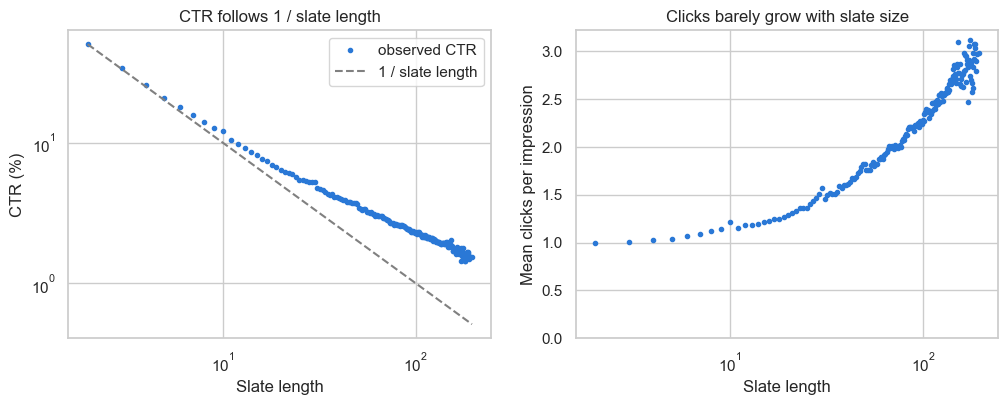

In [4]:
cpi = 100 * imp["n_clicks"].to_pandas().value_counts(normalize=True).sort_index()
print("Impressions with 0 clicks:", int((imp["n_clicks"] == 0).sum()))
print("% of impressions by number of clicks:")
print(cpi.head(6).round(2))
print(f"Mean clicks per impression: {n_clicks / n_imp:.2f}")

by_len = (imp.group_by("slate_len").agg(impressions=pl.len(), clicks=pl.col("n_clicks").sum())
          .sort("slate_len").to_pandas())
by_len["ctr"] = 100 * by_len.clicks / (by_len.slate_len * by_len.impressions)
by_len["mean_clicks"] = by_len.clicks / by_len.impressions
rho = stats.spearmanr(imp["slate_len"].to_numpy(), (imp["n_clicks"] / imp["slate_len"]).to_numpy()).statistic
print(f"\nSpearman(slate length, impression CTR) = {rho:.2f}")
print(by_len[by_len.slate_len.isin([2, 5, 10, 25, 50, 100, 200])].round(2).to_string(index=False))

d = by_len[by_len.impressions >= 200]
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(d.slate_len, d.ctr, "o", ms=3, label="observed CTR")
ax[0].plot(d.slate_len, 100 / d.slate_len, "--", color="grey", label="1 / slate length")
ax[0].set(xscale="log", yscale="log", xlabel="Slate length", ylabel="CTR (%)", title="CTR follows 1 / slate length")
ax[0].legend()
ax[1].plot(d.slate_len, d.mean_clicks, "o", ms=3)
ax[1].set(xscale="log", ylim=(0, None), xlabel="Slate length", ylabel="Mean clicks per impression", title="Clicks barely grow with slate size")
plt.savefig(FIG_DIR / "imp_02_ctr_by_slate_length.png", dpi=150, bbox_inches="tight")
plt.show()

# 2. Position in the slate

Position is the 1-based order of a candidate in the impression string. Pooled over all impressions CTR drops from 11% at position 1 to
2% at position 100, which looks like position bias. The two checks below show it is a **composition effect**:
* A null model that spreads each impression's clicks uniformly over its own slate (so it only uses the mix of slate lengths)
  reproduces the pooled curve within **0.3 percentage points**.
* With slate length held fixed (7, 10, 12, 25) CTR is flat across positions and a chi-square test of uniform clicks is far from
  significant (p between 0.63 and 0.85).

**Model Implications**
* The stored order carries **no display-rank information** (MIND documents that it was shuffled). `position` is not a feature and no
  position-bias correction is needed.

 position  exposures  clicks   ctr  null_ctr
        1    1897835  210899 11.11     11.07
        5    1631372  105863  6.49      6.51
       10    1421094   72312  5.09      5.09
       20    1086821   41931  3.86      3.87
       50     491220   12822  2.61      2.62
      100     155849    3105  1.99      2.00

Largest |observed - null| gap (positions with >= 10k exposures): 0.27 pp



CTR by position with slate length held fixed:
  length  7: n = 75,854 impressions, CTR 15.46% to 15.73%, chi2 p = 0.85
  length 10: n = 54,051 impressions, CTR 11.92% to 12.30%, chi2 p = 0.82
  length 12: n = 46,516 impressions, CTR 9.62% to 10.00%, chi2 p = 0.63
  length 25: n = 24,027 impressions, CTR 5.21% to 5.76%, chi2 p = 0.80


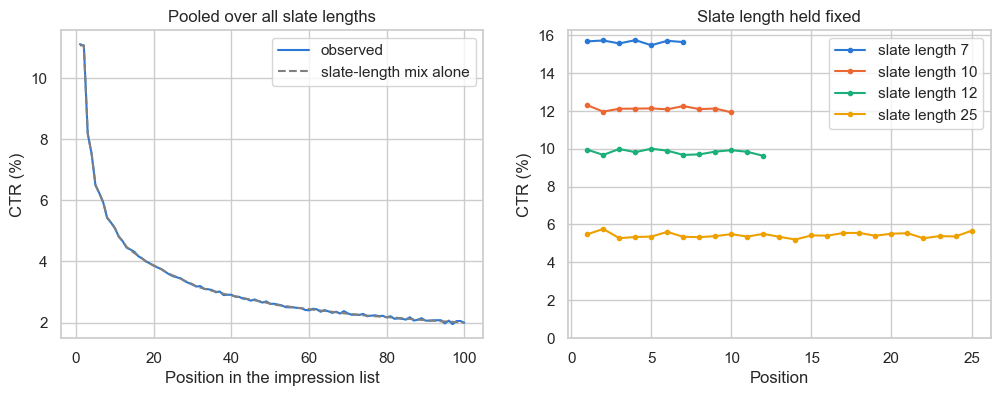

In [5]:
pos = (cand.group_by("position").agg(exposures=pl.len(), clicks=pl.col("clicked").sum())
       .sort("position").to_pandas())
pos["ctr"] = 100 * pos.clicks / pos.exposures

# Null model: if each impression's clicks were spread evenly over its own slate, the CTR at position p is
# sum over impressions with slate_len >= p of (clicks / slate_len), divided by the number of such impressions.
L = by_len.slate_len.values
imps = np.zeros(L.max() + 1)
clk = np.zeros(L.max() + 1)
imps[L] = by_len.impressions.values
clk[L] = by_len.clicks.values
share = clk / np.maximum(np.arange(L.max() + 1), 1)
imps_ge = np.cumsum(imps[::-1])[::-1]
share_ge = np.cumsum(share[::-1])[::-1]
pos["null_ctr"] = 100 * share_ge[pos.position] / imps_ge[pos.position]

print(pos[pos.position.isin([1, 5, 10, 20, 50, 100])].round(2).to_string(index=False))
big = pos[pos.exposures >= 10_000]
print(f"\nLargest |observed - null| gap (positions with >= 10k exposures): {(big.ctr - big.null_ctr).abs().max():.2f} pp")

# Slate length held fixed
fixed = (cand.join(imp.select("impression_uid", "slate_len"), on="impression_uid")
         .filter(pl.col("slate_len").is_in([7, 10, 12, 25]))
         .group_by("slate_len", "position").agg(exposures=pl.len(), clicks=pl.col("clicked").sum())
         .sort("slate_len", "position").to_pandas())
fixed["ctr"] = 100 * fixed.clicks / fixed.exposures
print("\nCTR by position with slate length held fixed:")
for Lf, g in fixed.groupby("slate_len"):
    chi = stats.chisquare(g.clicks.values)
    print(f"  length {Lf:>2}: n = {g.exposures.iloc[0]:>6,} impressions, CTR {g.ctr.min():.2f}% to {g.ctr.max():.2f}%, chi2 p = {chi.pvalue:.2f}")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
d = pos[pos.position <= 100]
ax[0].plot(d.position, d.ctr, label="observed")
ax[0].plot(d.position, d.null_ctr, "--", color="grey", label="slate-length mix alone")
ax[0].set(xlabel="Position in the impression list", ylabel="CTR (%)", title="Pooled over all slate lengths")
ax[0].legend()
for Lf, g in fixed.groupby("slate_len"):
    ax[1].plot(g.position, g.ctr, marker="o", ms=3, label=f"slate length {Lf}")
ax[1].set(ylim=(0, None), xlabel="Position", ylabel="CTR (%)", title="Slate length held fixed")
ax[1].legend()
plt.savefig(FIG_DIR / "imp_03_position.png", dpi=150, bbox_inches="tight")
plt.show()

# 3. Exposure-to-click funnel and what the labels mean

MIND records exactly two stages: an article is **exposed** in a slate, and it is **clicked or not**. There is no dwell time or share signal.
* 70.3 M exposures produce 2.87 M clicks (4.08%). Every impression and every user has at least one click (the click filter above).
* Of the 98,671 articles in the training news file only **24,641 were ever shown** and 15,292 ever clicked; the other 74,030 exist only
  in user histories. MSN's own candidate generation chose what was shown, and labels exist only for those pairs.

**Model Implications**
* Clicked = positive; shown and not clicked = explicit negative; in the history = past positive (input only); **everything else is
  unobserved, not negative**. The re-ranker trains on logged slates; the retrieval stage can only be scored against known clicks.

In [6]:
shown = cand["news_code"].n_unique()
clicked_articles = cand.filter(pl.col("clicked") == 1)["news_code"].n_unique()
catalogue = int(news["in_news_train"].sum())
history_entries = int(pl.read_parquet(PROCESSED / "impressions_train.parquet", columns=["user_code", "history_len"])
                      .unique("user_code")["history_len"].sum())

print("Funnel (training split)")
print(f"  exposures                     {n_exp:>14,}")
print(f"  clicks                        {n_clicks:>14,}   ({100 * n_clicks / n_exp:.2f}% of exposures)")
print(f"  impressions                   {n_imp:>14,}   (100% with >= 1 click)")
print(f"  articles in news file         {catalogue:>14,}")
print(f"  articles shown at least once  {shown:>14,}   ({100 * shown / catalogue:.1f}% of the news file)")
print(f"  articles clicked at least once{clicked_articles:>14,}   ({100 * clicked_articles / shown:.1f}% of shown)")
print(f"  users                         {n_users:>14,}   (100% with >= 1 click)")

print("\n(user, article) pairs")
print(f"  shown and clicked (y = 1)             {n_clicks:>14,}")
print(f"  shown, not clicked (y = 0)            {n_exp - n_clicks:>14,}")
print(f"  in the supplied history (input only)  {history_entries:>14,}")
print(f"  unobserved (label unknown)            {n_users * catalogue - n_exp - history_entries:>14,}")

Funnel (training split)
  exposures                         70,314,387
  clicks                             2,868,998   (4.08% of exposures)
  impressions                        1,897,835   (100% with >= 1 click)
  articles in news file                 98,671
  articles shown at least once          24,641   (25.0% of the news file)
  articles clicked at least once        15,292   (62.1% of shown)
  users                                667,880   (100% with >= 1 click)

(user, article) pairs
  shown and clicked (y = 1)                  2,868,998
  shown, not clicked (y = 0)                67,445,389
  in the supplied history (input only)      12,874,380
  unobserved (label unknown)            65,817,198,713


# 4. Label imbalance and negative sampling

* There are **23.5 explicit negatives per positive** overall and 16 in the median impression; 14% of impressions have fewer than 4 negatives.
* The agreed scheme (K = 4 unclicked articles per click from the same impression, one seeded draw without replacement) leaves at least
  **84%** of the explicit negatives unused; K = 8 and K = 16 leave 70% and 50% at the same number of training rows.

**Model Implications**
* Keep K = 4 as the baseline, report the discarded share, and run K = 8 / 16 as a sensitivity check. Exposed negatives are the right
  negatives for the re-ranker: they passed the same editorial filter as the positives and are the only pairs with a label.

Negatives per positive, pooled: 23.5
Negatives per positive, median impression: 16.2 (IQR 6.5 to 34.0)
Impressions with fewer than 4 negatives: 14.1%

K negatives per positive | negatives actually used per positive | explicit negatives never used | positives in impressions with < K negatives
  K =  4:  3.76 |   84% |  9.5%
  K =  8:  6.98 |   70% | 16.5%
  K = 16: 11.84 |   50% | 28.6%
  K = 24: 15.11 |   36% | 39.2%
  K = 32: 17.30 |   26% | 49.1%


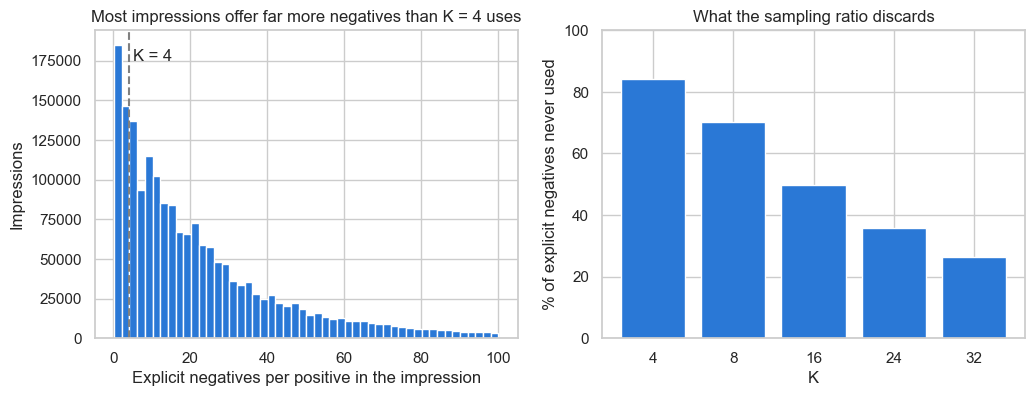

In [7]:
ratio = (imp["n_negatives"] / imp["n_clicks"]).to_pandas()
n_neg = n_exp - n_clicks
print(f"Negatives per positive, pooled: {n_neg / n_clicks:.1f}")
print(f"Negatives per positive, median impression: {ratio.median():.1f} (IQR {ratio.quantile(.25):.1f} to {ratio.quantile(.75):.1f})")
print(f"Impressions with fewer than 4 negatives: {100 * (imp['n_negatives'] < 4).mean():.1f}%")

print("\nK negatives per positive | negatives actually used per positive | explicit negatives never used | positives in impressions with < K negatives")
sweep = []
for K in [4, 8, 16, 24, 32]:
    used = int(imp.select(pl.min_horizontal(pl.col("n_negatives"), K * pl.col("n_clicks")).sum()).item())
    short = int(imp.filter(pl.col("n_negatives") < K)["n_clicks"].sum())
    sweep.append((K, used / n_clicks, 100 * (1 - used / n_neg), 100 * short / n_clicks))
    print(f"  K = {K:>2}: {used / n_clicks:5.2f} | {100 * (1 - used / n_neg):4.0f}% | {100 * short / n_clicks:4.1f}%")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(ratio[ratio <= 100], bins=50)
ax[0].axvline(4, color="grey", ls="--")
ax[0].text(5, ax[0].get_ylim()[1] * .9, "K = 4")
ax[0].set(xlabel="Explicit negatives per positive in the impression", ylabel="Impressions", title="Most impressions offer far more negatives than K = 4 uses")
ax[1].bar([str(s[0]) for s in sweep], [s[2] for s in sweep])
ax[1].set(xlabel="K", ylabel="% of explicit negatives never used", ylim=(0, 100), title="What the sampling ratio discards")
plt.savefig(FIG_DIR / "imp_04_negative_sampling.png", dpi=150, bbox_inches="tight")
plt.show()

# 5. Repeat exposure and history overlap

* **14% of exposures** re-show an article the same user already saw inside the window. CTR is 4.3% on first exposure, **2.6%** on a second
  exposure after the user passed it over, 5.1% after an earlier click; third or later exposures fall further.
* Candidates already in the user's supplied history are rare (0.3% of candidates, 0.6% of clicks) and are clicked at 8.4% when re-shown.

**Model Implications**
* "Previously shown and not clicked" is a usable, time-causal feature (`prior_exposure_count` with its outcome).
* History overlap is too small to be a leakage concern; the rows are kept.

Repeat exposures: 10,004,461 (14.2% of exposures)
    exposure            history  exposures  clicks  ctr  share_of_exposures
1st exposure                  -   60309926 2614241 4.33               85.77
2nd exposure     clicked before     320271   16470 5.14                0.46
2nd exposure passed over before    7359035  192664 2.62               10.47
3rd or later     clicked before     172084    5833 3.39                0.24
3rd or later passed over before    2153071   39790 1.85                3.06


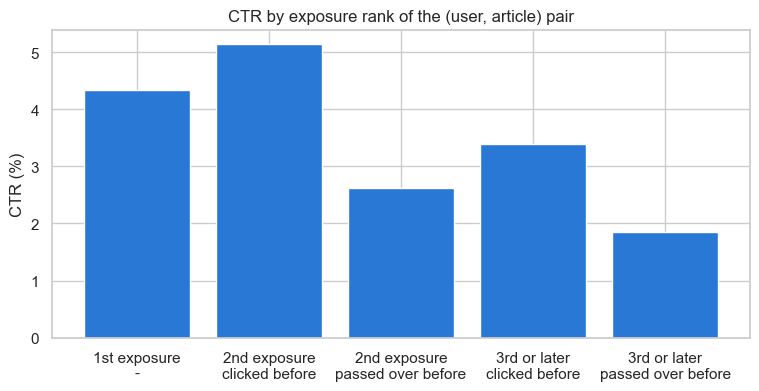

In [8]:
# Rank each (user, article) pair's exposures in time; prior_clicks = clicks on earlier exposures of the same pair
pair = pl.col("user_code").cast(pl.Int64) * 1_000_000 + pl.col("news_code")
rep = (cand.select("timestamp", "impression_uid", "clicked", pair.alias("pair"))
       .filter(pl.col("pair").is_duplicated())
       .sort(["pair", "timestamp", "impression_uid"])
       .with_columns(rank=pl.col("clicked").cum_count().over("pair"),
                     prior_clicks=pl.col("clicked").cast(pl.Int32).cum_sum().over("pair") - pl.col("clicked"))
       .filter(pl.col("rank") >= 2))
n_repeat = len(rep)
tbl = (rep.group_by(pl.when(pl.col("rank") == 2).then(pl.lit("2nd exposure")).otherwise(pl.lit("3rd or later")).alias("exposure"),
                    pl.when(pl.col("prior_clicks") > 0).then(pl.lit("clicked before")).otherwise(pl.lit("passed over before")).alias("history"))
       .agg(exposures=pl.len(), clicks=pl.col("clicked").sum()).sort("exposure", "history").to_pandas())
first = pd.DataFrame([{"exposure": "1st exposure", "history": "-", "exposures": n_exp - n_repeat, "clicks": n_clicks - tbl.clicks.sum()}])
tbl = pd.concat([first, tbl], ignore_index=True)
tbl["ctr"] = (100 * tbl.clicks / tbl.exposures).round(2)
tbl["share_of_exposures"] = (100 * tbl.exposures / n_exp).round(2)
print(f"Repeat exposures: {n_repeat:,} ({100 * n_repeat / n_exp:.1f}% of exposures)")
print(tbl.to_string(index=False))
del rep

labels = tbl.exposure + "\n" + tbl.history
plt.figure(figsize=(9, 4))
plt.bar(labels, tbl.ctr)
plt.title("CTR by exposure rank of the (user, article) pair")
plt.ylabel("CTR (%)")
plt.savefig(FIG_DIR / "imp_05_repeat_exposure.png", dpi=150, bbox_inches="tight")
plt.show()

In [9]:
# Candidates that are already in the user's supplied history
hist = (pl.read_parquet(PROCESSED / "impressions_train.parquet", columns=["impression_uid", "history"])
        .with_columns(h=pl.col("history").fill_null("").str.split(" ")
                      .list.eval(pl.element().filter(pl.element() != "").str.strip_prefix("N").cast(pl.Int32))))
slates = cand.group_by("impression_uid").agg(c=pl.col("news_code"), p=pl.col("news_code").filter(pl.col("clicked") == 1))
ov = (slates.join(hist, on="impression_uid")
      .select(cand_in_hist=pl.col("c").list.set_intersection("h").list.len(),
              clicks_in_hist=pl.col("p").list.set_intersection("h").list.len())
      .sum().row(0))
print(f"Candidates already in the user's history: {ov[0]:,} ({100 * ov[0] / n_exp:.2f}% of candidates)")
print(f"Clicked candidates already in the history: {ov[1]:,} ({100 * ov[1] / n_clicks:.2f}% of clicks), CTR when re-shown {100 * ov[1] / ov[0]:.1f}%")
del slates, hist

Candidates already in the user's history: 200,053 (0.28% of candidates)
Clicked candidates already in the history: 16,737 (0.58% of clicks), CTR when re-shown 8.4%


# 6. Slate composition: does category diversity or a stand-out article change clicks?

Two naive patterns look strong: diverse slates collect more clicks, and an article that is the only one of its category in the slate has a
much higher CTR. Both have to be checked at a **fixed slate length**, because longer slates collect more clicks and have lower per-article CTR.
* At a fixed length (10, 20, 30, 50) mean clicks per slate are **flat** across 1 to 12 categories.
* At a fixed length a unique-category article is **not** clicked more than majority-category articles (length 10: 11.5% vs 12.7%).

**Model Implications**
* Slate-level diversity and stand-out flags carry little independent signal; they are low-priority features. The whole log is
  conditioned on a click, so whether a diverse slate converts a non-clicking visit cannot be seen here.

All slates (note how mean slate length rises with the number of categories):
        slates  mean_slate_len  mean_clicks
n_cats                                     
1        42916            3.04         1.02
2       147567            2.77         1.01
3       108093            5.12         1.05
4       115451            7.52         1.10
5       105672           10.14         1.15
6        86559           13.56         1.21
7       102627           17.17         1.26
8       125312           22.88         1.35
9       144035           30.65         1.45
10      184453           37.88         1.56
11      227546           48.27         1.70
12      507604           77.01         2.02

Mean clicks per slate at fixed slate length:
slate_len    10    20    30    50
n_cats                           
2          1.19   NaN   NaN   NaN
3          1.19   NaN   NaN   NaN
4          1.19  1.24   NaN   NaN
5          1.20  1.28  1.50   NaN
6          1.21  1.25  1.54   NaN
7          1.22  1.32  

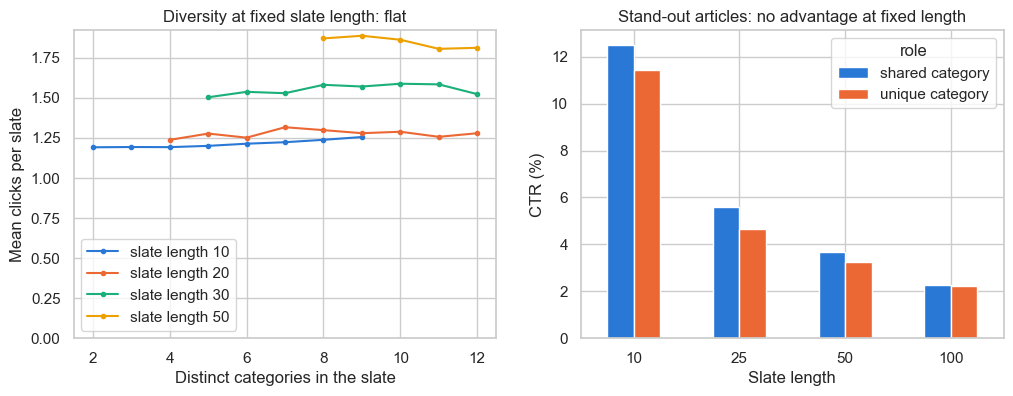

In [10]:
cc = (cand.join(news.select("news_code", pl.col("category").cast(pl.Categorical)), on="news_code")
      .join(imp.select("impression_uid", "slate_len"), on="impression_uid")
      .group_by("impression_uid", "category").agg(k=pl.len(), cat_clicks=pl.col("clicked").sum(), slate_len=pl.col("slate_len").first()))
per_slate = (cc.group_by("impression_uid").agg(n_cats=pl.len(), slate_len=pl.col("slate_len").first(), n_clicks=pl.col("cat_clicks").sum())
             .with_columns(n_cats=pl.min_horizontal("n_cats", pl.lit(12))).to_pandas())

naive = per_slate.groupby("n_cats").agg(slates=("n_clicks", "size"), mean_slate_len=("slate_len", "mean"), mean_clicks=("n_clicks", "mean"))
print("All slates (note how mean slate length rises with the number of categories):")
print(naive.round(2))
fixed_div = (per_slate[per_slate.slate_len.isin([10, 20, 30, 50])]
             .groupby(["slate_len", "n_cats"]).agg(slates=("n_clicks", "size"), mean_clicks=("n_clicks", "mean")).reset_index())
fixed_div = fixed_div[fixed_div.slates >= 200]
print("\nMean clicks per slate at fixed slate length:")
print(fixed_div.pivot(index="n_cats", columns="slate_len", values="mean_clicks").round(2))

# Stand-out articles: CTR of candidates whose category is unique in the slate vs shared, at exact slate lengths
role = (cc.filter(pl.col("slate_len").is_in([10, 25, 50, 100]))
        .with_columns(role=pl.when(pl.col("k") == 1).then(pl.lit("unique category")).otherwise(pl.lit("shared category")))
        .group_by("slate_len", "role").agg(exposures=pl.col("k").sum(), clicks=pl.col("cat_clicks").sum()).to_pandas())
role["ctr"] = 100 * role.clicks / role.exposures
print("\nCTR (%) of unique-category vs shared-category candidates at fixed slate length:")
print(role.pivot(index="slate_len", columns="role", values="ctr").round(2))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for Lf, g in fixed_div.groupby("slate_len"):
    ax[0].plot(g.n_cats, g.mean_clicks, marker="o", ms=3, label=f"slate length {Lf}")
ax[0].set(ylim=(0, None), xlabel="Distinct categories in the slate", ylabel="Mean clicks per slate", title="Diversity at fixed slate length: flat")
ax[0].legend()
role.pivot(index="slate_len", columns="role", values="ctr").plot(kind="bar", ax=ax[1], rot=0)
ax[1].set(xlabel="Slate length", ylabel="CTR (%)", title="Stand-out articles: no advantage at fixed length")
plt.savefig(FIG_DIR / "imp_06_slate_composition.png", dpi=150, bbox_inches="tight")
plt.show()
del cc, per_slate

# Summary

| Finding | Decision |
|---|---|
| Every impression has a click; CTR ≈ 1 / slate length | drop `slate_len`; evaluate per impression; CTR is a within-log yardstick |
| Position carries no display-rank information | drop `position`; no position-bias correction |
| Labels exist only for shown pairs; 75% of the news file is never a candidate | unobserved ≠ negative; retrieval scored against known clicks only |
| 23.5 negatives per positive; K = 4 discards ≥ 84% | keep K = 4, report the discarded share, K = 8 / 16 sensitivity |
| Re-shown passed-over articles are clicked less (2.6% vs 4.3%) | time-causal `prior_exposure_count` feature |
| Diversity and stand-out effects vanish at fixed slate length | slate-context features low priority |